# Đồ thị 13 Tỷ lệ nhãn 1 theo nhóm tuổi và giới tính

**Võ Minh Huy — 2311110117**

Tổng hợp DEATH_EVENT theo bốn nhóm tuổi và hai mã sex. Chỉ dùng 298 hồ sơ có nhãn hợp lệ. Tỷ lệ từng ô = số nhãn 1 trong ô / số hồ sơ có nhãn hợp lệ trong ô. Ghi cả tử số và mẫu số trên hình; không đưa hồ sơ chờ xác minh vào mẫu số.

Đây là tỷ lệ ghi nhận trong tập hồ sơ, không phải ước lượng nguy cơ đã điều chỉnh thời gian theo dõi hoặc xác suất dự đoán. Nhóm tuổi và sex đã được xử lý, có cả giá trị đã điền.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
for cot in ["age","MaNhomTuoi","sex","DEATH_EVENT"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot],errors="raise")
assert len(du_lieu) == 299
assert du_lieu["age"].between(40,95).all() and du_lieu["sex"].isin([0,1]).all()
ma_tu_tuoi = np.select([du_lieu["age"]<50,du_lieu["age"]<60,du_lieu["age"]<70],[1,2,3],default=4)
assert np.array_equal(ma_tu_tuoi,du_lieu["MaNhomTuoi"].to_numpy())
nhan = du_lieu["DEATH_EVENT"]
if (nhan.notna() & ~nhan.isin([0,1])).any():
    raise ValueError("Có nhãn ngoài miền 0/1.")
hop_le = du_lieu.loc[nhan.isin([0,1])].copy()
assert len(hop_le) == 298 and nhan.isna().sum() == 1
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/13_heatmap_ty_le_nhan"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
quy_mo = pd.DataFrame({"SoHoSoAfter":[299],"SoNhanHopLe":[len(hop_le)],
    "SoNhanChoXacMinhKhongTinh":[int(nhan.isna().sum())]})
quy_mo


,SoHoSoAfter,SoNhanHopLe,SoNhanChoXacMinhKhongTinh
0,299,298,1


In [2]:
chi_muc = pd.MultiIndex.from_product([[1,2,3,4],[0,1]],names=["MaNhomTuoi","sex"])
bang = hop_le.groupby(["MaNhomTuoi","sex"])["DEATH_EVENT"].agg(SoNhanHopLe="size",SoNhan1="sum").reindex(chi_muc,fill_value=0)
bang["SoNhan1"] = bang["SoNhan1"].astype(int)
bang["SoNhan0"] = bang["SoNhanHopLe"] - bang["SoNhan1"]
bang["TyLeNhan1"] = bang["SoNhan1"] / bang["SoNhanHopLe"].replace(0,np.nan)
bang["SoChoXacMinh"] = du_lieu.loc[nhan.isna()].groupby(["MaNhomTuoi","sex"]).size().reindex(chi_muc,fill_value=0)
assert bang["SoNhanHopLe"].sum() == 298 and bang["SoNhan1"].sum() == 95
assert bang["SoNhan0"].sum() == 203 and bang["SoChoXacMinh"].sum() == 1
assert bang["TyLeNhan1"].dropna().between(0,1).all()
assert np.isclose(np.average(bang["TyLeNhan1"],weights=bang["SoNhanHopLe"]),95/298)
bang_tong_hop = bang.reset_index()
bang_tong_hop["GioiTinh"] = bang_tong_hop["sex"].map({0:"Nữ",1:"Nam"})
bang_tong_hop["TyLeNhan1PhanTram"] = 100*bang_tong_hop["TyLeNhan1"]
bang_tong_hop[["MaNhomTuoi","GioiTinh","SoNhanHopLe","SoNhan0","SoNhan1","SoChoXacMinh","TyLeNhan1PhanTram"]].round(2)


,MaNhomTuoi,GioiTinh,SoNhanHopLe,SoNhan0,SoNhan1,SoChoXacMinh,TyLeNhan1PhanTram
0,1,Nữ,18,14,4,0,22.22
1,1,Nam,24,20,4,0,16.67
2,2,Nữ,27,18,9,0,33.33
3,2,Nam,50,41,9,0,18.00
4,3,Nữ,38,28,10,0,26.32
5,3,Nam,72,45,27,1,37.50
6,4,Nữ,22,11,11,0,50.00
7,4,Nam,47,26,21,0,44.68


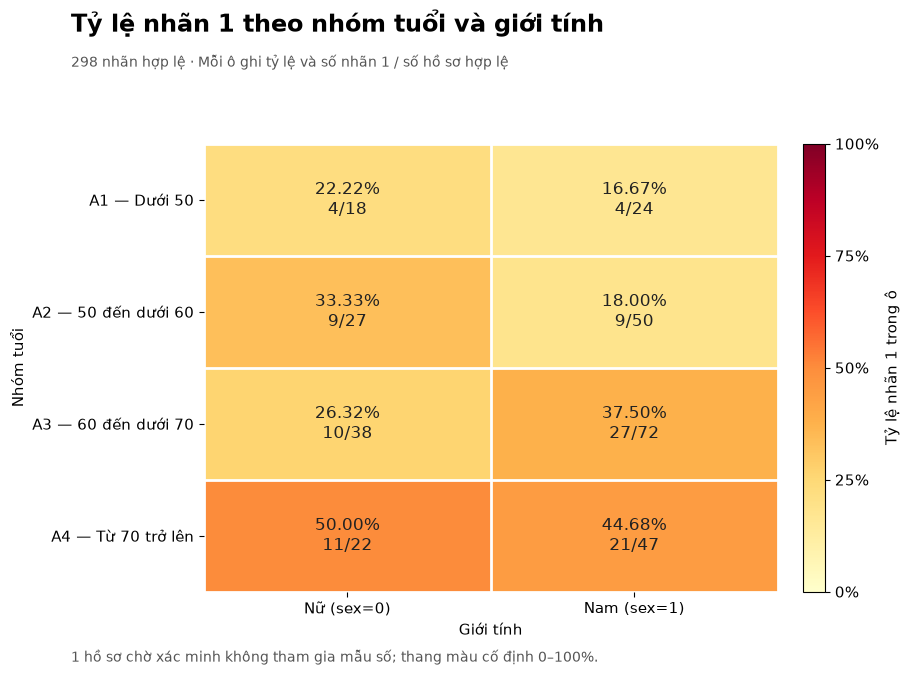

In [3]:
ty_le = bang["TyLeNhan1"].unstack("sex").reindex(index=[1,2,3,4],columns=[0,1])
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(9.5,7))
fig.subplots_adjust(top=0.78,bottom=0.14,left=0.22,right=0.88)
fig.text(0.08,0.94,"Tỷ lệ nhãn 1 theo nhóm tuổi và giới tính",fontsize=17,weight="bold")
fig.text(0.08,0.89,"298 nhãn hợp lệ · Mỗi ô ghi tỷ lệ và số nhãn 1 / số hồ sơ hợp lệ",color="#555555",fontsize=10)
bang_mau = plt.get_cmap("YlOrRd").copy()
bang_mau.set_bad("#dddddd")
anh = ax.imshow(np.ma.masked_invalid(ty_le.to_numpy()),cmap=bang_mau,vmin=0,vmax=1,aspect="auto")
for i, tuoi in enumerate([1,2,3,4]):
    for j, sex in enumerate([0,1]):
        r = bang.loc[(tuoi,sex)]
        text = f'{100*r["TyLeNhan1"]:.2f}%\n{int(r["SoNhan1"])}/{int(r["SoNhanHopLe"])}' if r["SoNhanHopLe"]>0 else "Không có mẫu"
        ax.text(j,i,text,ha="center",va="center",fontsize=12,
            color="white" if r["TyLeNhan1"]>0.6 else "#222222")
ax.set_xticks([0,1],labels=["Nữ (sex=0)","Nam (sex=1)"])
ax.set_yticks([0,1,2,3],labels=["A1 — Dưới 50","A2 — 50 đến dưới 60","A3 — 60 đến dưới 70","A4 — Từ 70 trở lên"])
ax.set(xlabel="Giới tính",ylabel="Nhóm tuổi")
ax.set_xticks(np.arange(-0.5,2,1),minor=True)
ax.set_yticks(np.arange(-0.5,4,1),minor=True)
ax.grid(which="minor",color="white",linewidth=2)
ax.tick_params(which="minor",bottom=False,left=False)
for s in ax.spines.values():
    s.set_visible(False)
cbar=fig.colorbar(anh,ax=ax,fraction=0.045,pad=0.04,ticks=[0,0.25,0.5,0.75,1],format=PercentFormatter(1))
cbar.set_label("Tỷ lệ nhãn 1 trong ô")
fig.text(0.08,0.04,"1 hồ sơ chờ xác minh không tham gia mẫu số; thang màu cố định 0–100%.",fontsize=10,color="#555555")
fig.savefig(thu_muc_kq / "13_heatmap_ty_le_nhan.png",dpi=300,bbox_inches="tight",facecolor="white")
quy_mo.to_csv(thu_muc_kq / "quy_mo_python.csv",index=False,encoding="utf-8-sig")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

So sánh các ô bằng tỷ lệ và luôn đọc kèm tử số/mẫu số. Tỷ lệ cao hơn chưa chứng minh nhóm đó có nguy cơ cao hơn trong dân số; cỡ nhóm khác nhau, một số nhóm ít hồ sơ và chưa điều chỉnh các yếu tố khác hoặc thời gian theo dõi.

Thang màu cố định 0–100%; đây không phải ma trận tương quan. Tổng số hồ sơ hợp lệ của tám ô bằng 298, tổng nhãn 1 bằng 95. Khi gộp tỷ lệ phải dùng mẫu số từng ô làm trọng số. Một hồ sơ chờ xác minh vẫn giữ trong file after, không được tự gán nhãn. Tuổi và sex có thể chứa giá trị đã điền ở N02 và N01.
